<a href="https://colab.research.google.com/github/n1m1nd33p/Practical-ML/blob/main/Logistic_Regression_Wine_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Lab – Practical 7: Logistic Regression

**Dataset:** Wine Recognition Dataset (Scikit-learn built-in dataset)  
**Task:** Binary classification using Logistic Regression

## Objectives
1. Implement Logistic Regression for binary classification.
2. Evaluate the model using a Confusion Matrix.
3. Plot and analyse the ROC Curve and calculate AUC.





In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
wine = load_wine()

X_all = pd.DataFrame(wine.data, columns=wine.feature_names)
y_all = pd.Series(wine.target, name="wine_class")

print("Original dataset shape:", X_all.shape)
print("Original class names:", wine.target_names)
print("\nOriginal class counts:")
print(y_all.value_counts().sort_index())
display(X_all.head())

Original dataset shape: (178, 13)
Original class names: ['class_0' 'class_1' 'class_2']

Original class counts:
wine_class
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
binary_mask = y_all.isin([0, 1])

X = X_all.loc[binary_mask].copy()
y = y_all.loc[binary_mask].copy()

print("Binary dataset shape:", X.shape)
print("\nBinary class counts:")
print(y.value_counts().sort_index())
print("\nTarget mapping: 0 =", wine.target_names[0],
      "| 1 =", wine.target_names[1])

Binary dataset shape: (130, 13)

Binary class counts:
wine_class
0    59
1    71
Name: count, dtype: int64

Target mapping: 0 = class_0 | 1 = class_1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 104
Testing samples: 26


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

results = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Class": y_pred,
    "Probability of Class 1": y_prob
})

display(results.head(10))

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[wine.target_names[0], wine.target_names[1]],
    zero_division=0
))

Accuracy : 0.9615 (96.15%)
Precision: 1.0000
Recall   : 0.9286
F1-score : 0.9630

Classification Report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14

    accuracy                           0.96        26
   macro avg       0.96      0.96      0.96        26
weighted avg       0.96      0.96      0.96        26



##  Confusion Matrix

1.   List item
2.   List item



Confusion Matrix:
[[12  0]
 [ 1 13]]


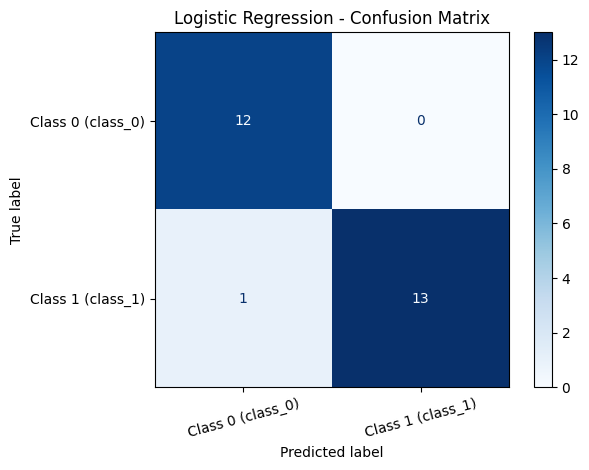

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

display_labels = [
    f"Class 0 ({wine.target_names[0]})",
    f"Class 1 ({wine.target_names[1]})"
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



##  ROC Curve and AUC

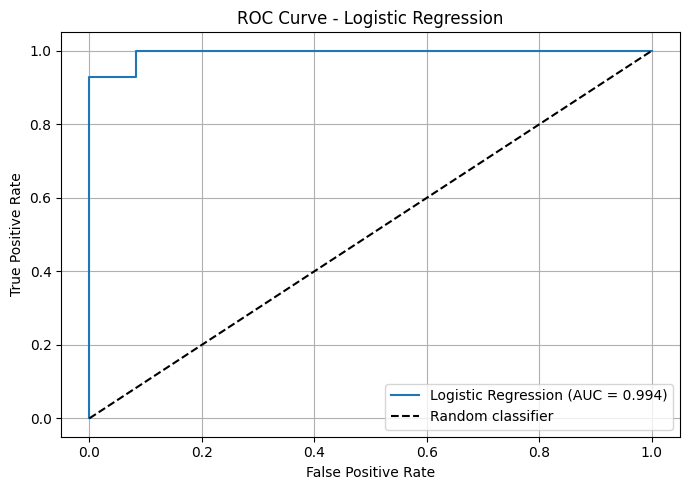

ROC-AUC score: 0.994


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=1)
auc_value = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

print("ROC-AUC score:", round(auc_value, 4))

In [ ]:
summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, auc_value]
})

display(summary)

print("Practical completed: Logistic Regression binary classification,")
print("Confusion Matrix evaluation, and ROC-AUC analysis.")

,Metric,Score
0,Accuracy,0.961538
1,Precision,1.000000
2,Recall,0.928571
3,F1-score,0.962963
4,ROC-AUC,0.994048


Practical completed: Logistic Regression binary classification,
Confusion Matrix evaluation, and ROC-AUC analysis.
